# Exploratory Data Analysis (EDA) — TED Talks Dataset

**Student-level Python project**

## Objective
In this notebook, we will explore the TED Talks dataset before using it for a content-based recommendation system. We will use simple Pandas, Matplotlib and Seaborn functions to understand the data, find quality issues, and explore relationships between columns.

### Analysis included
1. Initial data inspection and data types
2. Data quality checks
3. **Univariate analysis** — one variable at a time
4. TED-specific analysis: topics, speakers, views, duration, dates, languages, events, occupations, comments and related talks
5. **Bivariate analysis** — relationships between two variables
6. **Multivariate analysis** — patterns involving three or more variables
7. Basic cleaning and creation of `combined_text`
8. Final findings and saving a cleaned CSV

> **Before running:** Put your dataset CSV in the same folder as this notebook. If your file has a different name, update `file_path` in the next cell. The notebook checks for expected columns and skips analyses when a column is unavailable.

## 1. Import libraries

We use:
- **Pandas** to read and analyze tabular data.
- **Matplotlib** and **Seaborn** to create charts.
- **Regular expressions (`re`)** to help clean and inspect text.
- **`ast`** to safely inspect columns that may contain list-like values stored as strings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import ast
from collections import Counter
from IPython.display import display

# Keep chart style simple and consistent
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

Change the file name below to match your CSV. We keep the original data in `df` and will create a separate copy later for cleaning.

In [3]:
file_path = r"C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\ted_talks_cleaned.csv"  # Change this if your CSV has a different name

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 4005
Number of columns: 19


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


## 3. Understand the dataset

First, check column names, data types, and the number of missing values. A column's Pandas dtype does not always tell us its analysis type: for example, `talk_id` may be numeric in storage but is an identifier, not a measurement.

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nDataset information:")
df.info()

print("\nSummary of numerical columns:")
display(df.describe().T)

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Data types:


,data_type
talk_id,int64
title,object
speaker_1,object
all_speakers,object
occupations,object
about_speakers,object
views,int64
recorded_date,object
published_date,object
event,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   talk_id         4005 non-null   int64 
 1   title           4005 non-null   object
 2   speaker_1       4005 non-null   object
 3   all_speakers    4005 non-null   object
 4   occupations     4005 non-null   object
 5   about_speakers  4005 non-null   object
 6   views           4005 non-null   int64 
 7   recorded_date   4004 non-null   object
 8   published_date  4005 non-null   object
 9   event           4005 non-null   object
 10  native_lang     4005 non-null   object
 11  available_lang  4005 non-null   object
 12  comments        4005 non-null   int64 
 13  duration        4005 non-null   int64 
 14  topics          4005 non-null   object
 15  related_talks   4005 non-null   object
 16  url             4005 non-null   object
 17  description     4005 non-null 

,count,mean,std,min,25%,50%,75%,max
talk_id,4005.0,1.243254e+04,1.744758e+04,1.0,1252.0,2333.0,23777.0,62794.0
views,4005.0,2.148006e+06,3.451226e+06,0.0,882069.0,1375508.0,2133110.0,65051954.0
comments,4005.0,1.500587e+02,2.473467e+02,0.0,46.0,89.0,162.0,6449.0
duration,4005.0,7.240112e+02,3.617755e+02,60.0,393.0,738.0,974.0,3922.0


### 3.1 Expected columns

The notebook is designed around these columns from the TED Talks dataset:

- **Numerical:** `views`, `comments`, `duration`
- **Categorical:** `speaker_1`, `occupations`, `event`, `native_lang`
- **Datetime:** `recorded_date`, `published_date`
- **Text:** `title`, `all_speakers`, `about_speakers`, `description`, `transcript`
- **Other:** `talk_id`, `url`, `topics`, `available_lang`, `related_talks`

The next cell reports whether these columns are present. If your file uses slightly different column names, update the names in the notebook to match your file.

In [5]:
expected_columns = [
    "views", "comments", "duration",
    "speaker_1", "occupations", "event", "native_lang",
    "recorded_date", "published_date",
    "title", "all_speakers", "about_speakers", "description", "transcript",
    "talk_id", "url", "topics", "available_lang", "related_talks"
]

for col in expected_columns:
    status = "Present" if col in df.columns else "Not found"
    print(f"{col}: {status}")

views: Present
comments: Present
duration: Present
speaker_1: Present
occupations: Present
event: Present
native_lang: Present
recorded_date: Present
published_date: Present
title: Present
all_speakers: Present
about_speakers: Present
description: Present
transcript: Present
talk_id: Present
url: Present
topics: Present
available_lang: Present
related_talks: Present


## 4. Data quality checks

Before analysis, check missing values, exact duplicate rows, and duplicate talk IDs. Do not remove every unusual record automatically: investigate whether it is an error first.

In [6]:
# Missing values in each column
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary)

print("Exact duplicate rows:", df.duplicated().sum())

if "talk_id" in df.columns:
    print("Missing talk IDs:", df["talk_id"].isna().sum())
    print("Duplicate talk IDs:", df["talk_id"].duplicated().sum())
    print("Unique talk IDs:", df["talk_id"].nunique())

,missing_count,missing_percent
recorded_date,1,0.02
title,0,0.00
talk_id,0,0.00
speaker_1,0,0.00
all_speakers,0,0.00
about_speakers,0,0.00
occupations,0,0.00
views,0,0.00
published_date,0,0.00
event,0,0.00


Exact duplicate rows: 0
Missing talk IDs: 0
Duplicate talk IDs: 0
Unique talk IDs: 4005


# Part A — Univariate Analysis

**Univariate analysis** means examining one variable at a time. We study its values, distribution, categories, or text length without comparing it to another variable.

## 5. Numerical variables

Columns: `views`, `comments`, `duration`

For numerical variables, we examine:
- Mean, median, minimum, maximum and standard deviation
- Quartiles and interquartile range (IQR)
- Skewness
- Histogram to see the distribution
- Box plot to identify potential outliers

A point shown as an outlier by a box plot is only a potential outlier. It should be investigated, not automatically deleted.

In [7]:
num_cols = [c for c in ["views", "comments", "duration"] if c in df.columns]

if num_cols:
    # Convert selected columns to numeric where possible
    for col in num_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    numeric_summary = df[num_cols].describe().T
    numeric_summary["median"] = df[num_cols].median()
    numeric_summary["IQR"] = (
        df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
    )
    numeric_summary["skewness"] = df[num_cols].skew()

    display(numeric_summary)
else:
    print("No expected numerical columns were found.")

,count,mean,std,min,25%,50%,75%,max,median,IQR,skewness
views,4005.0,2.148006e+06,3.451226e+06,0.0,882069.0,1375508.0,2133110.0,65051954.0,1375508.0,1251041.0,8.185744
comments,4005.0,1.500587e+02,2.473467e+02,0.0,46.0,89.0,162.0,6449.0,89.0,116.0,9.660689
duration,4005.0,7.240112e+02,3.617755e+02,60.0,393.0,738.0,974.0,3922.0,738.0,581.0,1.185608


Saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\views_histogram_boxplot.png


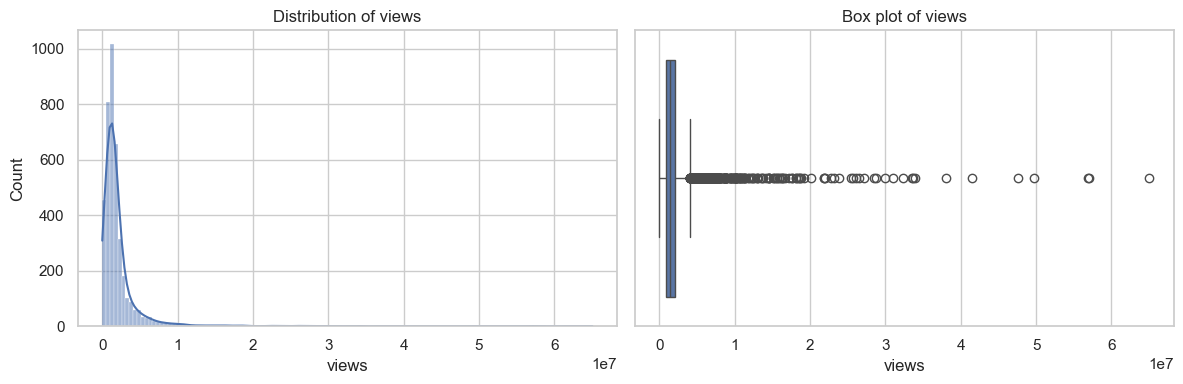

Saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\comments_histogram_boxplot.png


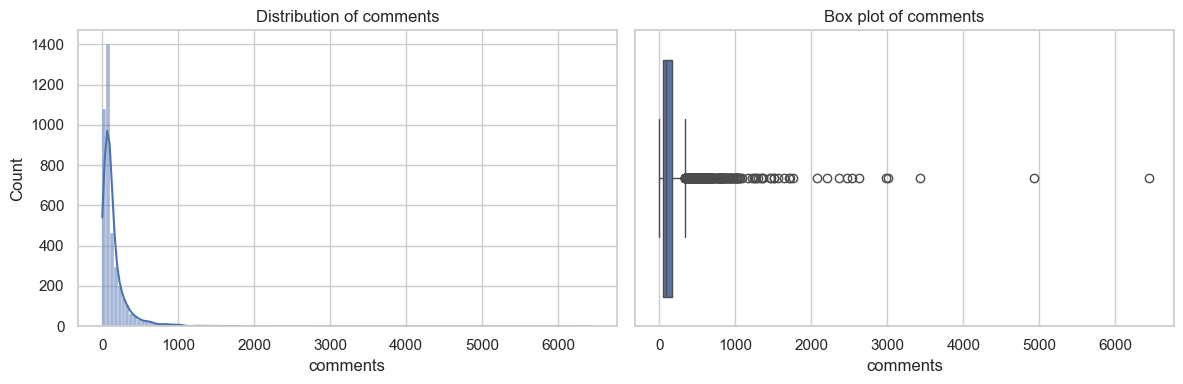

Saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\duration_histogram_boxplot.png


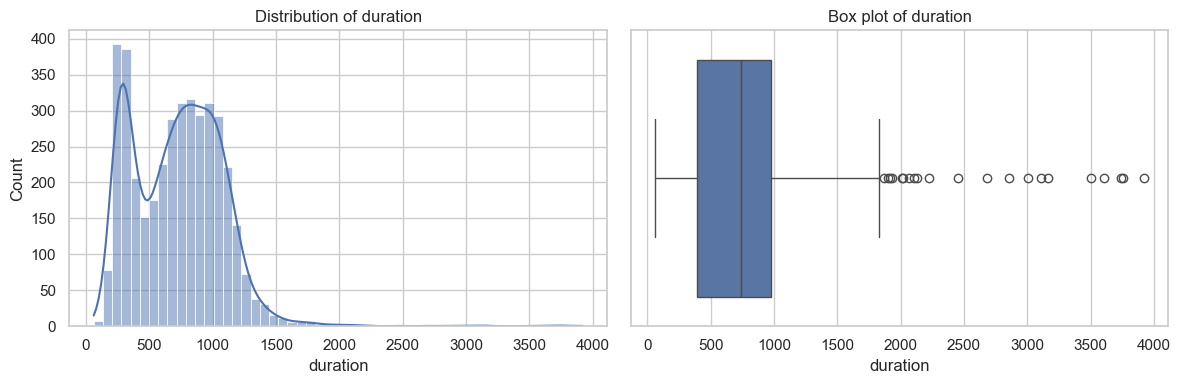

In [41]:

import os

# Create output folder in the current working directory
output_dir = os.path.join(os.getcwd(), "output")
os.makedirs(output_dir, exist_ok=True)

# Histogram and box plot for each numerical column
for col in num_cols:
    values = df[col].dropna()

    if values.empty:
        print(f"No valid numeric values in {col}")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(values, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)

    sns.boxplot(x=values, ax=axes[1])
    axes[1].set_title(f"Box plot of {col}")
    axes[1].set_xlabel(col)

    plt.tight_layout()

    # Save both plots together as one image
    file_name = f"{col}_histogram_boxplot.png"
    save_path = os.path.join(output_dir, file_name)

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)


### How to interpret numerical charts

- If the mean is much larger than the median, the data may be right-skewed.
- A long tail in the histogram means some values are much larger or smaller than most values.
- The box plot highlights values outside the usual IQR-based range.
- For TED Talks, a small number of talks may have very high views or comments. Confirm this using the charts and summary statistics.

## 6. Categorical variables

Columns: `speaker_1`, `occupations`, `event`, `native_lang`

For categorical columns, count how often each category occurs, calculate its percentage, and check how many unique categories are present. Bar charts make the most common categories easier to compare.


--- speaker_1 ---
Missing values: 0
Number of unique categories: 3274

Top 10 categories:


,count
speaker_1,
Alex Gendler,34
Iseult Gillespie,19
Emma Bryce,12
Daniel Finkel,11
Hans Rosling,10
Alex Rosenthal,10
Juan Enriquez,9
Greg Gage,9
Chris Anderson,8


Graph saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\speaker_1_top10_categories.png


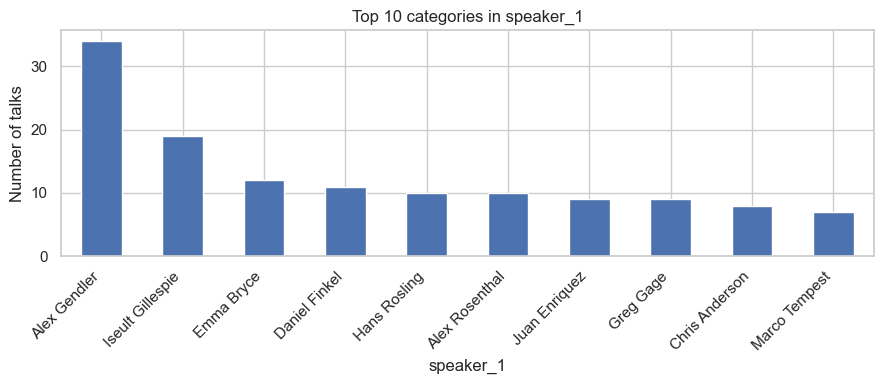


--- occupations ---
Missing values: 0
Number of unique categories: 2050

Top 10 categories:


,count
occupations,
Unknown,522
{0: ['writer']},53
{0: ['journalist']},47
{0: ['entrepreneur']},42
{0: ['artist']},41
{0: ['architect']},38
{0: ['designer']},37
{0: ['neuroscientist']},32
{0: ['psychologist']},31


Graph saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\occupations_top10_categories.png


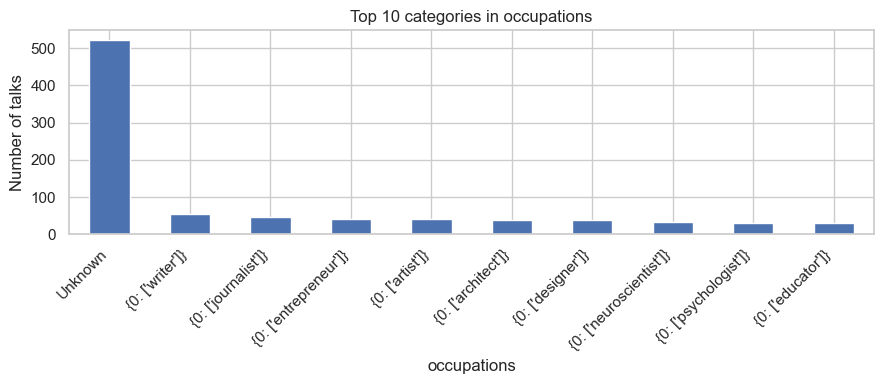


--- event ---
Missing values: 0
Number of unique categories: 459

Top 10 categories:


,count
event,
TED-Ed,556
TED2017,96
TED2018,96
TED2019,91
TED2014,84
TED2009,81
TED2016,75
TED2015,75
TED2013,75


Graph saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\event_top10_categories.png


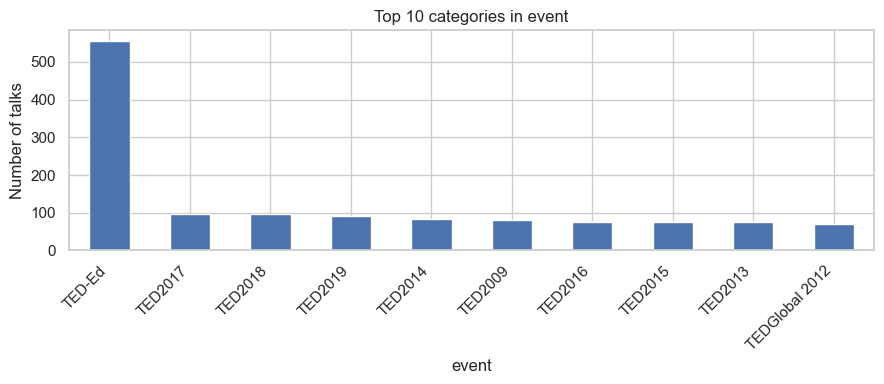


--- native_lang ---
Missing values: 0
Number of unique categories: 12

Top 10 categories:


,count
native_lang,
en,3957
es,27
fr,9
ja,3
hi,2
de,1
pt,1
ko,1
pt-br,1


Graph saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\native_lang_top10_categories.png


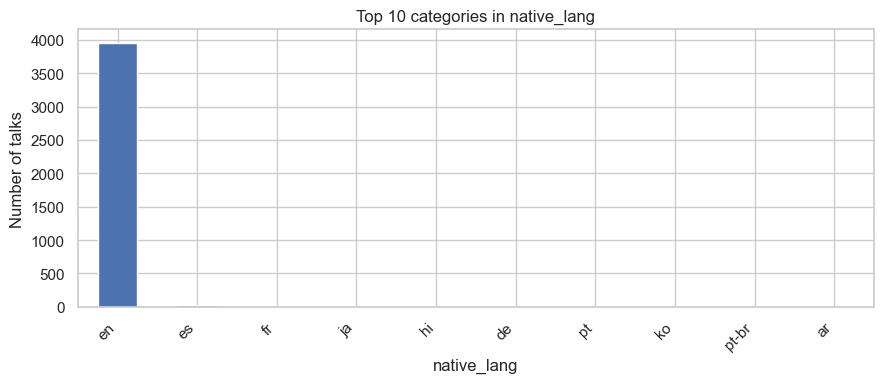

In [42]:

import os

# Create output folder if it doesn't exist
output_dir = os.path.join(os.getcwd(), "output")
os.makedirs(output_dir, exist_ok=True)

cat_cols = [
    c for c in ["speaker_1", "occupations", "event", "native_lang"]
    if c in df.columns
]

for col in cat_cols:
    print(f"\n--- {col} ---")
    print("Missing values:", df[col].isna().sum())
    print("Number of unique categories:", df[col].nunique())

    print("\nTop 10 categories:")
    display(df[col].value_counts(dropna=False).head(10).to_frame("count"))

    top_categories = df[col].dropna().astype(str).value_counts().head(10)

    if not top_categories.empty:
        fig, ax = plt.subplots(figsize=(9, 4))

        top_categories.plot(kind="bar", ax=ax)
        ax.set_title(f"Top 10 categories in {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Number of talks")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()

        # Save the graph as a PNG image
        file_name = f"{col}_top10_categories.png"
        save_path = os.path.join(output_dir, file_name)

        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Graph saved: {save_path}")

        plt.show()
        plt.close(fig)


### How to interpret categorical results

- The most frequent category shows what appears most often in the dataset.
- **Cardinality** means the number of unique categories.
- A rare category is not automatically incorrect and should not be removed without a reason.
- Check for inconsistent formatting, such as extra spaces or different capitalization.

## 7. Datetime variables

Columns: `recorded_date`, `published_date`

Convert date columns to datetime format, then find the earliest and latest dates. We can also count talks by year and month. Invalid dates become `NaT`, which should be counted and reviewed.

In [10]:
date_cols = [c for c in ["recorded_date", "published_date"] if c in df.columns]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

    print(f"\n--- {col} ---")
    print("Missing or invalid dates:", df[col].isna().sum())
    print("Earliest date:", df[col].min())
    print("Latest date:", df[col].max())

    if df[col].notna().any():
        print("Date range:", df[col].max() - df[col].min())


--- recorded_date ---
Missing or invalid dates: 1
Earliest date: 1984-02-02 00:00:00
Latest date: 2020-04-30 00:00:00
Date range: 13237 days 00:00:00

--- published_date ---
Missing or invalid dates: 0
Earliest date: 2006-06-27 00:00:00
Latest date: 2020-04-30 00:00:00
Date range: 5056 days 00:00:00


,number_of_talks
published_year,
2006,49
2007,119
2008,185
2009,215
2010,230
2011,255
2012,303
2013,242
2014,240


Graph saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\ted_talks_published_by_year.png


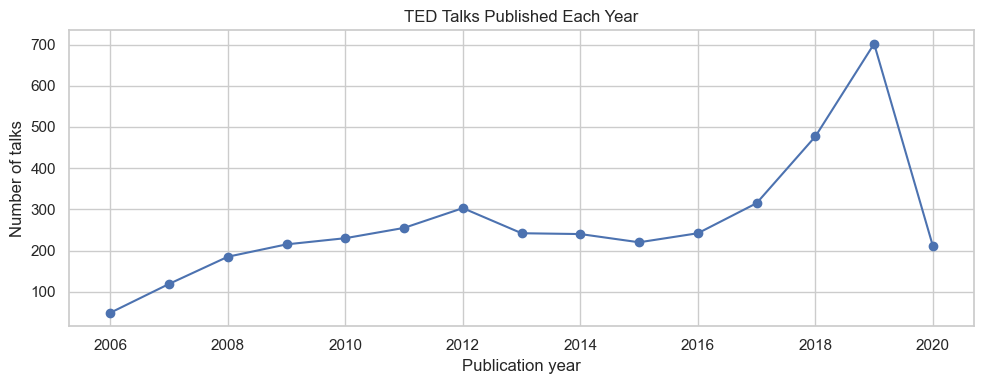

Graph saved: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\output\ted_talks_by_publication_month.png


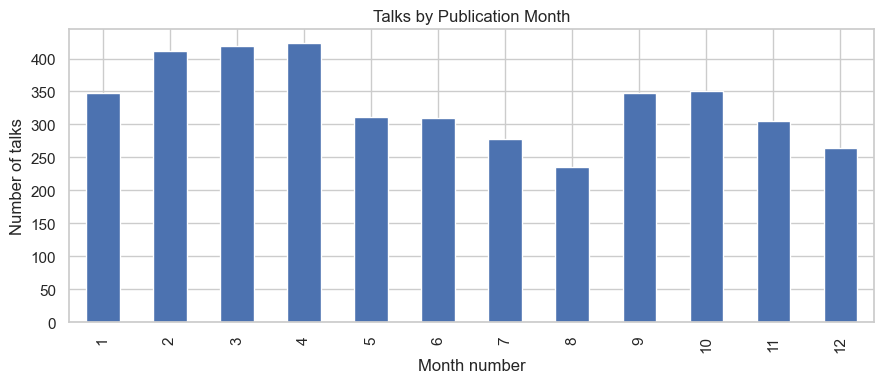

In [43]:

import os

# Create output folder if it doesn't exist
output_dir = os.path.join(os.getcwd(), "output")
os.makedirs(output_dir, exist_ok=True)

# Publication trend by year
if "published_date" in df.columns:
    valid_dates = df["published_date"].dropna()

    if not valid_dates.empty:
        df["published_year"] = df["published_date"].dt.year
        yearly_counts = df["published_year"].value_counts().sort_index()

        display(yearly_counts.rename("number_of_talks").to_frame())

        # Yearly publication trend
        fig, ax = plt.subplots(figsize=(10, 4))
        yearly_counts.plot(kind="line", marker="o", ax=ax)

        ax.set_title("TED Talks Published Each Year")
        ax.set_xlabel("Publication year")
        ax.set_ylabel("Number of talks")
        plt.tight_layout()

        # Save yearly trend graph
        save_path = os.path.join(
            output_dir, "ted_talks_published_by_year.png"
        )
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Graph saved: {save_path}")

        plt.show()
        plt.close(fig)

        # Month distribution
        month_counts = (
            df["published_date"].dt.month.value_counts().sort_index()
        )

        fig, ax = plt.subplots(figsize=(9, 4))
        month_counts.plot(kind="bar", ax=ax)

        ax.set_title("Talks by Publication Month")
        ax.set_xlabel("Month number")
        ax.set_ylabel("Number of talks")
        plt.tight_layout()

        # Save monthly distribution graph
        save_path = os.path.join(
            output_dir, "ted_talks_by_publication_month.png"
        )
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Graph saved: {save_path}")

        plt.show()
        plt.close(fig)


**Interpretation tip:** A gap between dates does not automatically mean data is missing. Talks may simply not have been published every day. Look for trends and unexpected date values rather than assuming every date should have a record.

## 8. Text variables

Columns: `title`, `description`, `transcript`, `about_speakers`

For text, we check missing or empty entries, word counts, and unusually short or long text. These checks help us decide whether the text is useful for a content-based recommendation system.

In [12]:
text_cols = [
    c for c in ["title", "all_speakers", "about_speakers",
                "description", "transcript"]
    if c in df.columns
]

for col in text_cols:
    text = df[col].fillna("").astype(str).str.strip()
    print(f"\n--- {col} ---")
    print("Missing values:", df[col].isna().sum())
    print("Empty entries:", text.eq("").sum())


--- title ---
Missing values: 0
Empty entries: 0

--- all_speakers ---
Missing values: 0
Empty entries: 0

--- about_speakers ---
Missing values: 0
Empty entries: 0

--- description ---
Missing values: 0
Empty entries: 0

--- transcript ---
Missing values: 0
Empty entries: 0



Word-count summary for title:


,title_word_count
count,4005.000000
mean,6.735331
std,2.438527
min,1.000000
25%,5.000000
50%,6.000000
75%,8.000000
max,17.000000


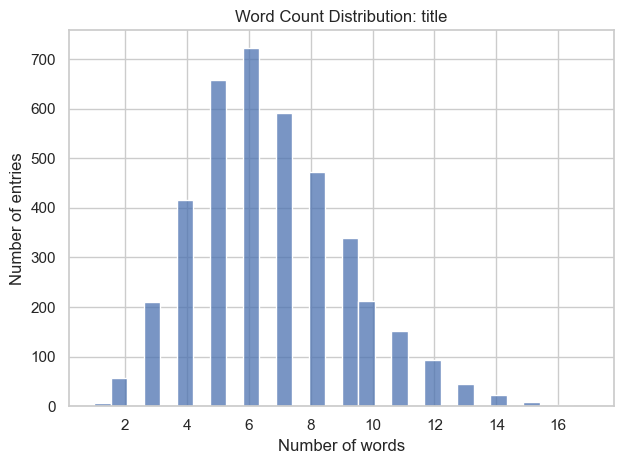


Word-count summary for description:


,description_word_count
count,4005.000000
mean,58.195506
std,19.430348
min,9.000000
25%,43.000000
50%,57.000000
75%,72.000000
max,143.000000


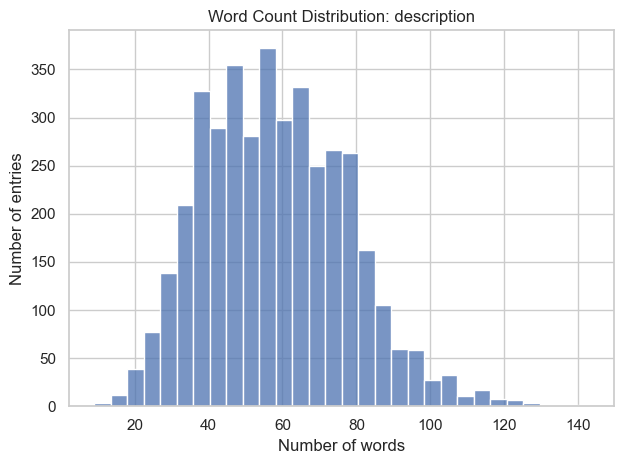


Word-count summary for transcript:


,transcript_word_count
count,4005.000000
mean,1796.845693
std,1004.008431
min,2.000000
25%,928.000000
50%,1753.000000
75%,2445.000000
max,11121.000000


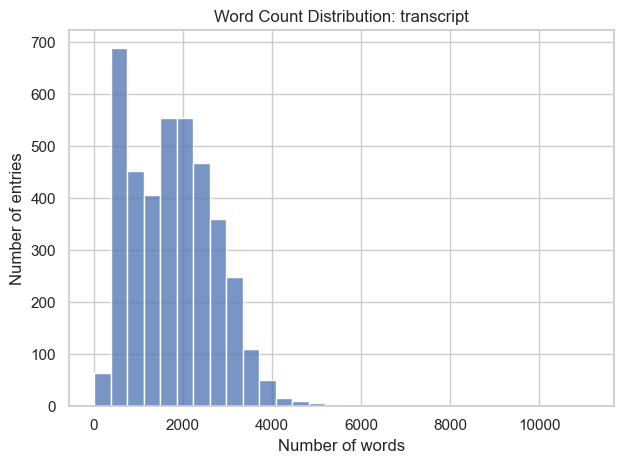


Word-count summary for about_speakers:


,about_speakers_word_count
count,4005.000000
mean,22.525094
std,16.026504
min,1.000000
25%,15.000000
50%,22.000000
75%,28.000000
max,238.000000


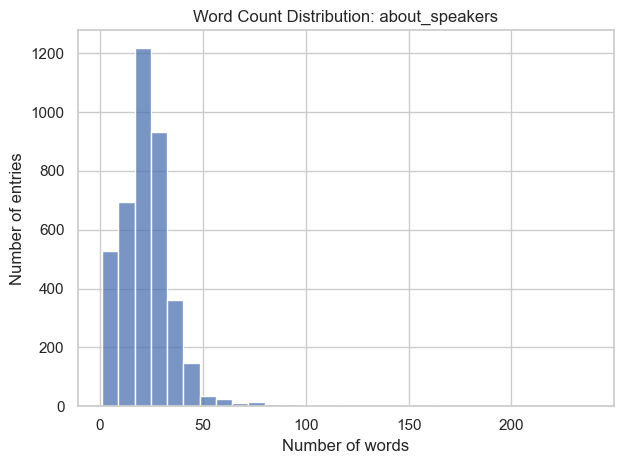

In [44]:

# Calculate word counts for important text columns
word_count_cols = [
    c for c in ["title", "description", "transcript", "about_speakers"]
    if c in df.columns
]

for col in word_count_cols:
    text = df[col].fillna("").astype(str).str.strip()
    df[f"{col}_word_count"] = text.apply(lambda x: len(x.split()) if x else 0)

    print(f"\nWord-count summary for {col}:")
    display(df[f"{col}_word_count"].describe().to_frame())

    # Plot word-count distribution
    sns.histplot(df[f"{col}_word_count"], bins=30)
    plt.title(f"Word Count Distribution: {col}")
    plt.xlabel("Number of words")
    plt.ylabel("Number of entries")
    plt.tight_layout()

    # Save graph in the output folder
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)

    plt.savefig(
        os.path.join(output_dir, f"{col}_word_count_distribution.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [45]:
# Inspect the shortest and longest text entries
for col in word_count_cols:
    count_col = f"{col}_word_count"

    print(f"\nShortest entries in {col}:")
    display(df.nsmallest(5, count_col)[[col, count_col]])

    print(f"Longest entries in {col}:")
    display(df.nlargest(5, count_col)[[col, count_col]])


Shortest entries in title:


,title,title_word_count
175,"""Tembererana""",1
242,"""Clonie""",1
2344,"""Rollercoaster""",1
2421,"""Awoo""",1
2967,"""Chasms""",1


Longest entries in title:


,title,title_word_count
3853,The real story of Rosa Parks -- and why we nee...,17
1872,How we found the worst place to park in New Yo...,16
2977,Why it's too hard to start a business in Afric...,16
3511,The lies our culture tells us about what matte...,16
801,"A test that finds 3x more breast tumors, and w...",15



Shortest entries in description:


...

,transcript,transcript_word_count
3965,"Whitney Pennington Rodgers: Hello everyone, an...",11121
3973,"Chris Anderson: Well, hello, Helen. Very nice ...",10789
3966,Chris Anderson: Welcome to TED Connects. This ...,10075
3768,[Citizens of the world] [We face a global cris...,9841
2334,Chris Anderson: Hello. Welcome to this TED Dia...,9185



Shortest entries in about_speakers:


,about_speakers,about_speakers_word_count
961,Unknown,1
989,Unknown,1
1420,Unknown,1
2421,Unknown,1
2478,Unknown,1


Longest entries in about_speakers:


,about_speakers,about_speakers_word_count
2753,{0: 'Aaron Duffy began employing visual tricks...,238
3598,"{0: 'Eddie Jaku OAM, born Abraham Jakubowicz i...",198
3070,{0: 'Ariel Anbar is a scientist and educator i...,195
3006,{0: 'Shane is a strong believer in the power o...,168
3370,{0: 'I’m an Associate Professor in the Departm...,164


### Basic word-frequency analysis

The following cell counts common words from titles and descriptions. It is a simple first look at the text, not a complete NLP pipeline. Very common words such as “the” and “and” may dominate the results, so they should be removed before drawing conclusions about meaningful topics.

In [46]:
text_for_words = []
for col in [c for c in ["title", "description"] if c in df.columns]:
    text_for_words.extend(df[col].dropna().astype(str).str.lower().tolist())

combined_words_text = " ".join(text_for_words)
words = re.findall(r"\b[a-z]+\b", combined_words_text)
word_counts = Counter(words)

print("20 most common words:")
display(pd.DataFrame(word_counts.most_common(20), columns=["word", "count"]))

20 most common words:


,word,count
0,the,11904
1,and,8131
2,of,7290
3,to,7007
4,a,6872
5,in,4696
6,that,2647
7,how,2645
8,s,2643
9,for,2221


## 9. Topics analysis

The `topics` column may store several topics for each talk. We inspect its format first, then count topics and plot the most frequent ones.

The helper below supports common formats: Python lists, list-like strings, or comma-separated text. If your dataset uses a different format, inspect the sample values and adjust it.

In [47]:
if "topics" in df.columns:
    display(df["topics"].dropna().head(10).to_frame())

,topics
0,"['alternative energy', 'cars', 'climate change..."
1,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,"['computers', 'entertainment', 'interface desi..."
3,"['MacArthur grant', 'activism', 'business', 'c..."
4,"['children', 'creativity', 'culture', 'dance',..."
5,"['architecture', 'collaboration', 'culture', '..."
6,"['Christianity', 'God', 'atheism', 'comedy', '..."
7,"['God', 'atheism', 'brain', 'cognitive science..."
8,"['Christianity', 'God', 'culture', 'happiness'..."
9,"['TED Prize', 'culture', 'entertainment', 'fil..."


Number of topics per talk:


,topic_count
count,4005.000000
mean,7.915106
std,3.904362
min,1.000000
25%,5.000000
50%,7.000000
75%,10.000000
max,33.000000


,talk_count
science,993
technology,979
culture,680
tedx,581
global issues,574
ted-ed,563
society,557
design,518
social change,512
animation,487


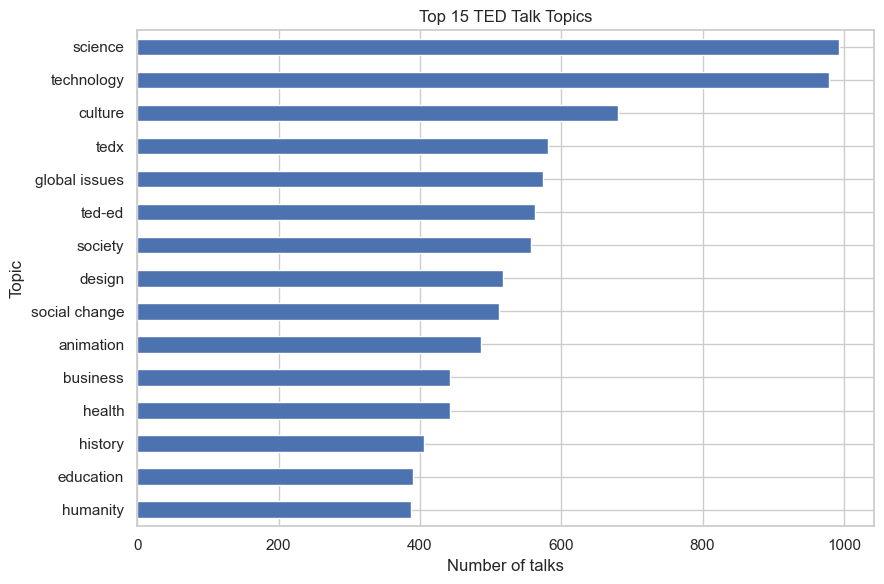

In [48]:

def parse_multi_value(value):
    """Convert a list-like cell or comma-separated string into a list of values."""
    if pd.isna(value):
        return []

    if isinstance(value, (list, tuple, set)):
        items = list(value)
    else:
        text = str(value).strip()
        if not text:
            return []

        # Try to interpret strings such as "['science', 'technology']"
        try:
            parsed = ast.literal_eval(text)
            if isinstance(parsed, (list, tuple, set)):
                items = list(parsed)
            else:
                items = text.split(",")
        except (ValueError, SyntaxError):
            items = text.split(",")

    return [str(item).strip().strip("'\"") for item in items
            if str(item).strip().strip("'\"")]


if "topics" in df.columns:
    df["topic_list"] = df["topics"].apply(parse_multi_value)
    df["topic_count"] = df["topic_list"].apply(len)

    print("Number of topics per talk:")
    display(df["topic_count"].describe().to_frame())

    topic_counts = Counter(
        topic.lower() for topic_list in df["topic_list"] for topic in topic_list
        if topic
    )
    top_topics = pd.Series(topic_counts).sort_values(ascending=False).head(15)

    display(top_topics.to_frame("talk_count"))

    if not top_topics.empty:
        top_topics.sort_values().plot(kind="barh", figsize=(9, 6))
        plt.title("Top 15 TED Talk Topics")
        plt.xlabel("Number of talks")
        plt.ylabel("Topic")
        plt.tight_layout()

        # Save graph in the output folder
        output_dir = os.path.join(os.getcwd(), "output")
        os.makedirs(output_dir, exist_ok=True)

        plt.savefig(
            os.path.join(output_dir, "top_15_ted_talk_topics.png"),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
else:
    print("The topics column is not available.")


## 10. Speaker analysis

Use `speaker_1` to count the primary speaker per talk. The `all_speakers` column may contain multiple names in one cell, so inspect it before splitting it. The simple counts below focus on `speaker_1`; they do not claim to count every co-speaker.

Unique primary speakers: 3274


,number_of_talks
speaker_1,
Alex Gendler,34
Iseult Gillespie,19
Emma Bryce,12
Daniel Finkel,11
Hans Rosling,10
Alex Rosenthal,10
Juan Enriquez,9
Greg Gage,9
Chris Anderson,8


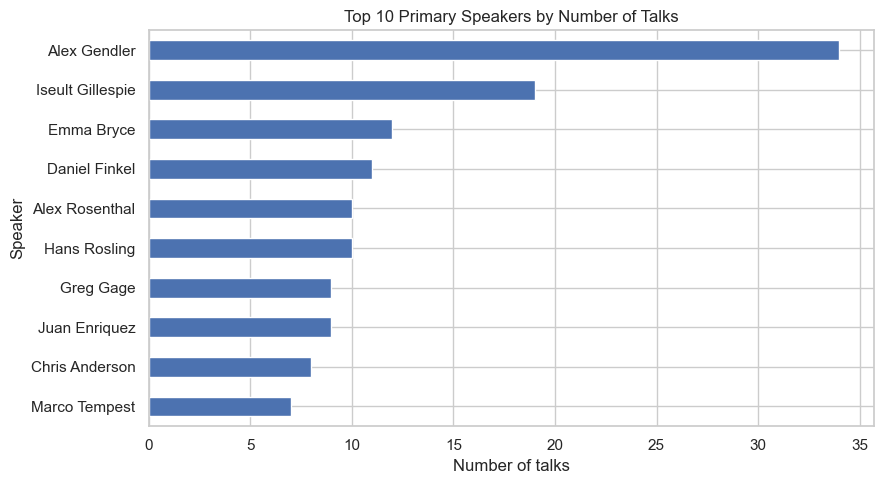


Examples from all_speakers:


,all_speakers
0,{0: 'Al Gore'}
1,{0: 'Hans Rosling'}
2,{0: 'David Pogue'}
3,{0: 'Majora Carter'}
4,{0: 'Sir Ken Robinson'}
5,{0: 'Joshua Prince-Ramus'}
6,{0: 'Julia Sweeney'}
7,{0: 'Dan Dennett'}
8,{0: 'Rick Warren'}
9,{0: 'Jehane Noujaim'}


Unique non-empty all_speakers entries: 3307


In [18]:
if "speaker_1" in df.columns:
    print("Unique primary speakers:", df["speaker_1"].nunique())

    top_speakers = df["speaker_1"].dropna().astype(str).value_counts().head(10)
    display(top_speakers.to_frame("number_of_talks"))

    top_speakers.sort_values().plot(kind="barh", figsize=(9, 5))
    plt.title("Top 10 Primary Speakers by Number of Talks")
    plt.xlabel("Number of talks")
    plt.ylabel("Speaker")
    plt.tight_layout()
    plt.show()

if "all_speakers" in df.columns:
    print("\nExamples from all_speakers:")
    display(df["all_speakers"].dropna().head(10).to_frame())
    print("Unique non-empty all_speakers entries:",
          df["all_speakers"].dropna().nunique())

## 11. Views, duration and comments: required checks

The summary statistics and distribution plots for these numerical columns were already created in Section 5. Here we add the specific outputs requested for the project: top 10 talks by views and comments, and basic checks for invalid negative values.

In [19]:
# Top 10 most-viewed talks
if "views" in df.columns:
    view_cols = [c for c in ["talk_id", "title", "speaker_1", "views"] if c in df.columns]
    print("Top 10 most-viewed talks:")
    display(df.nlargest(10, "views")[view_cols])

# Top 10 talks with the most comments
if "comments" in df.columns:
    comment_cols = [c for c in ["talk_id", "title", "speaker_1", "comments"] if c in df.columns]
    print("Top 10 talks by comments:")
    display(df.nlargest(10, "comments")[comment_cols])

# Check negative values
for col in [c for c in ["views", "comments", "duration"] if c in df.columns]:
    print(f"{col} negative values:", (df[col] < 0).sum())

Top 10 most-viewed talks:


,talk_id,title,speaker_1,views
4,66,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,1569,Your body language may shape who you are,Amy Cuddy,57074270
2062,2405,This is what happens when you reply to spam email,James Veitch,56932551
646,848,How great leaders inspire action,Simon Sinek,49730580
796,1042,The power of vulnerability,Brené Brown,47544833
1724,2034,How to speak so that people want to listen,Julian Treasure,41504331
2108,2458,Inside the mind of a master procrastinator,Tim Urban,37976820
1366,1647,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2724,13587,My philosophy for a happy life,Sam Berns,33691484
1898,2225,The next outbreak? We're not ready,Bill Gates,33521780


Top 10 talks by comments:


,talk_id,title,speaker_1,comments
94,113,Militant atheism,Richard Dawkins,6449
4,66,Do schools kill creativity?,Sir Ken Robinson,4931
617,801,Science can answer moral questions,Sam Harris,3424
1735,2045,How do you explain consciousness?,David Chalmers,3006
197,229,My stroke of insight,Jill Bolte Taylor,2984
1296,1569,Your body language may shape who you are,Amy Cuddy,2633
911,1164,Taking imagination seriously,Janet Echelman,2529
799,1045,On reading the Koran,Lesley Hazleton,2463
631,824,The danger of science denial,Michael Specter,2366
796,1042,The power of vulnerability,Brené Brown,2209


views negative values: 0
comments negative values: 0
duration negative values: 0


## 12. Language, event and occupation analysis

`native_lang` describes a talk's native language. `available_lang` may list several available languages. Events and occupations can help describe the dataset and can be useful for filtering recommendations.

In [20]:
# Native language counts
if "native_lang" in df.columns:
    display(df["native_lang"].value_counts().head(15).to_frame("talk_count"))

# Inspect available language structure before parsing
if "available_lang" in df.columns:
    print("Examples of available_lang:")
    display(df["available_lang"].dropna().head(10).to_frame())

    available_lists = df["available_lang"].apply(parse_multi_value)
    df["available_lang_count"] = available_lists.apply(len)

    print("Available-language count per talk:")
    display(df["available_lang_count"].describe().to_frame())

    lang_counts = Counter(
        language.lower() for languages in available_lists for language in languages
        if language
    )
    display(pd.Series(lang_counts).sort_values(ascending=False).head(15)
            .to_frame("number_of_entries"))

,talk_count
native_lang,
en,3957
es,27
fr,9
ja,3
hi,2
de,1
pt,1
ko,1
pt-br,1


Examples of available_lang:


,available_lang
0,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
1,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de..."
2,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr..."
3,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es..."
4,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs..."
5,"['ar', 'bg', 'en', 'es', 'fr', 'he', 'it', 'ja..."
6,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
7,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
8,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
9,"['ar', 'bg', 'cs', 'en', 'es', 'fa', 'fr', 'he..."


Available-language count per talk:


,available_lang_count
count,4005.000000
mean,25.304120
std,9.038567
min,1.000000
25%,20.000000
50%,25.000000
75%,31.000000
max,73.000000


,number_of_entries
en,4005
es,3915
pt-br,3899
fr,3863
ar,3841
zh-tw,3818
zh-cn,3788
ko,3755
ru,3676
tr,3610


Top categories in event:


,count
event,
TED-Ed,556
TED2017,96
TED2018,96
TED2019,91
TED2014,84
TED2009,81
TED2016,75
TED2015,75
TED2013,75


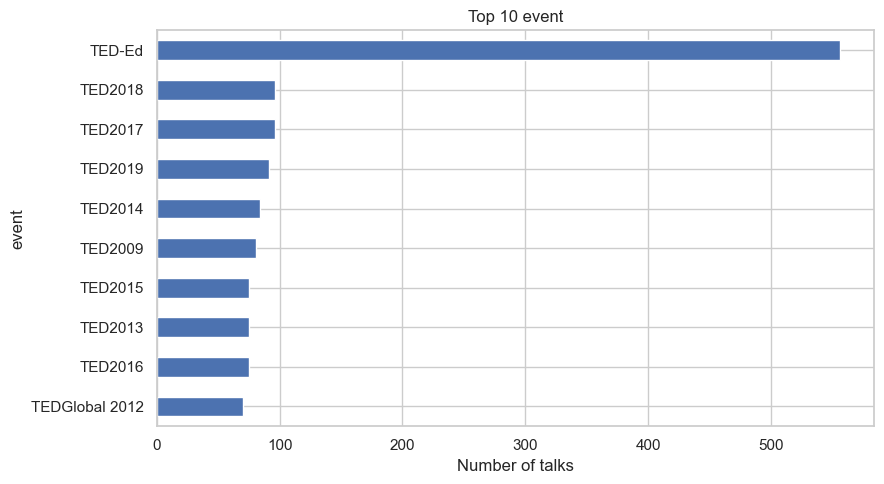

Top categories in occupations:


,count
occupations,
Unknown,522
{0: ['writer']},53
{0: ['journalist']},47
{0: ['entrepreneur']},42
{0: ['artist']},41
{0: ['architect']},38
{0: ['designer']},37
{0: ['neuroscientist']},32
{0: ['psychologist']},31


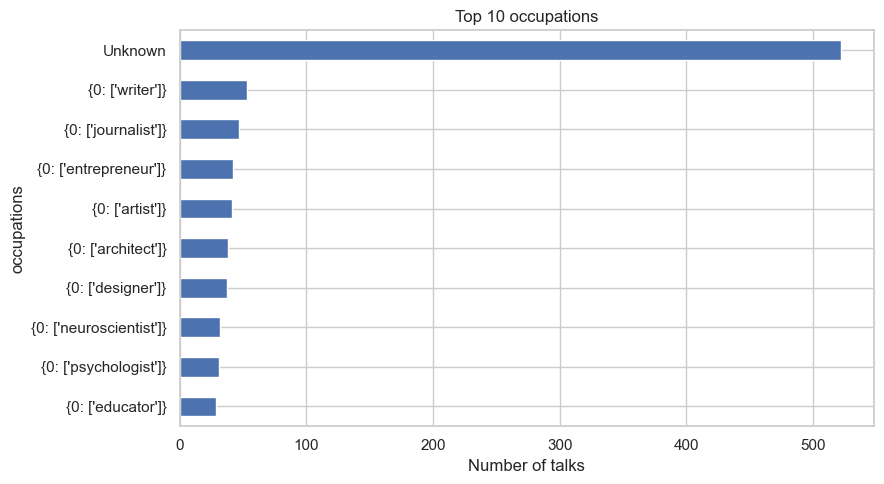

In [49]:

# Top events and occupations
for col in [c for c in ["event", "occupations"] if c in df.columns]:
    counts = df[col].dropna().astype(str).value_counts().head(10)
    print(f"Top categories in {col}:")
    display(counts.to_frame("count"))

    if not counts.empty:
        counts.sort_values().plot(kind="barh", figsize=(9, 5))
        plt.title(f"Top 10 {col}")
        plt.xlabel("Number of talks")
        plt.ylabel(col)
        plt.tight_layout()

        # Save graph in the output folder
        output_dir = os.path.join(os.getcwd(), "output")
        os.makedirs(output_dir, exist_ok=True)

        plt.savefig(
            os.path.join(output_dir, f"top_10_{col}.png"),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


## 13. Related talks analysis

`related_talks` may contain a list of talk IDs or a list-like string. First inspect the structure, then count related entries. We also check whether referenced IDs appear in the dataset when the format can be interpreted as numeric IDs.

In [22]:
if "related_talks" in df.columns:
    print("Examples of related_talks:")
    display(df["related_talks"].dropna().head(10).to_frame())

    df["related_talk_list"] = df["related_talks"].apply(parse_multi_value)
    df["related_talk_count"] = df["related_talk_list"].apply(len)

    print("Related-talk count summary:")
    display(df["related_talk_count"].describe().to_frame())

Examples of related_talks:


,related_talks
0,"{243: 'New thinking on the climate crisis', 54..."
1,"{2056: ""Own your body's data"", 2296: 'A visual..."
2,"{1725: '10 top time-saving tech tips', 2274: '..."
3,{1041: '3 stories of local eco-entrepreneurshi...
4,"{865: 'Bring on the learning revolution!', 173..."
5,{750: 'Building a theater that remakes itself'...
6,"{22: 'Why people believe weird things', 94: ""L..."
7,"{71: 'A life of purpose', 2011: 'Is religion g..."
8,"{94: ""Let's teach religion -- all religion -- ..."
9,{2228: 'How virtual reality can create the ult...


Related-talk count summary:


,related_talk_count
count,4005.000000
mean,6.491885
std,0.860817
min,1.000000
25%,6.000000
50%,6.000000
75%,7.000000
max,12.000000


In [23]:
if "related_talks" in df.columns and "talk_id" in df.columns:
    known_ids = set(pd.to_numeric(df["talk_id"], errors="coerce").dropna().astype(int))

    def extract_numeric_ids(items):
        ids = []
        for item in items:
            # Common case: a related talk is stored as an ID such as 123
            match = re.search(r"\d+", str(item))
            if match:
                ids.append(int(match.group()))
        return ids

    related_ids = [
        related_id
        for items in df["related_talk_list"]
        for related_id in extract_numeric_ids(items)
    ]

    if related_ids:
        valid_count = sum(item in known_ids for item in related_ids)
        print("Total related-talk references interpreted as IDs:", len(related_ids))
        print("References found in talk_id:", valid_count)
        print("References not found in talk_id:", len(related_ids) - valid_count)
    else:
        print("Could not interpret related_talks as numeric IDs. Inspect the values and adjust parsing.")

Total related-talk references interpreted as IDs: 24055
References found in talk_id: 23885
References not found in talk_id: 170


# Part B — Bivariate Analysis

**Bivariate analysis** studies the relationship between two variables. It can help answer questions such as:
- Do talks with more comments also tend to have more views?
- Is duration related to views?
- Do different events have different view distributions?
- Do publication years show different average view counts?

A relationship or correlation does not prove that one variable causes the other.

## 14. Numerical variable vs. numerical variable

We use scatter plots to visually compare two numerical columns and a correlation matrix to measure linear relationships between numerical variables.

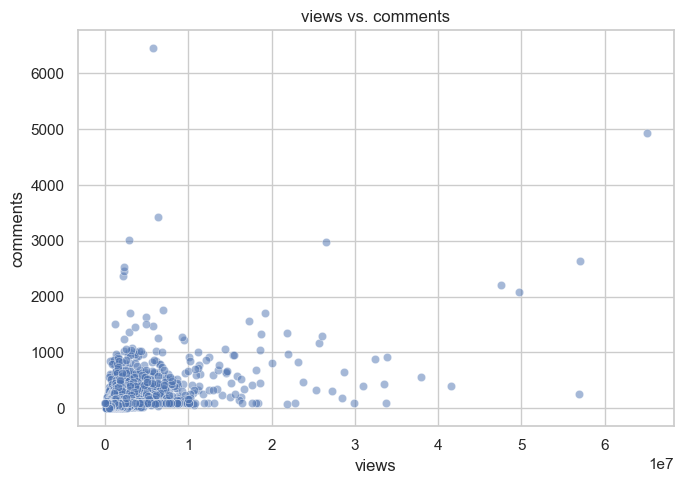

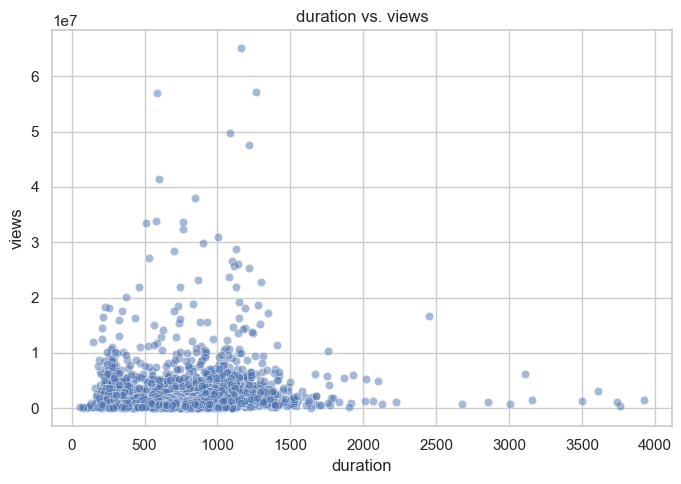

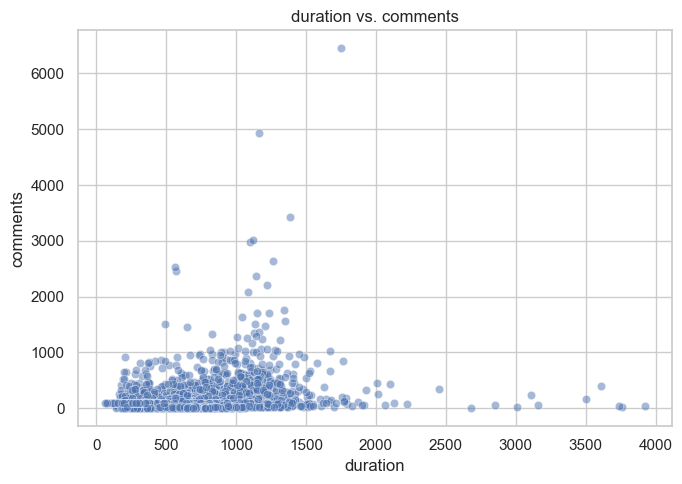

In [50]:

# Scatter plots for useful pairs
pairs = [
    ("views", "comments"),
    ("duration", "views"),
    ("duration", "comments")
]

for x_col, y_col in pairs:
    if x_col in df.columns and y_col in df.columns:
        plot_df = df[[x_col, y_col]].dropna()

        if not plot_df.empty:
            plt.figure(figsize=(7, 5))
            sns.scatterplot(data=plot_df, x=x_col, y=y_col, alpha=0.5)
            plt.title(f"{x_col} vs. {y_col}")
            plt.tight_layout()

            # Save graph in the output folder
            output_dir = os.path.join(os.getcwd(), "output")
            os.makedirs(output_dir, exist_ok=True)

            plt.savefig(
                os.path.join(output_dir, f"{x_col}_vs_{y_col}.png"),
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()


,views,comments,duration
views,1.000000,0.467730,0.073642
comments,0.467730,1.000000,0.198694
duration,0.073642,0.198694,1.000000


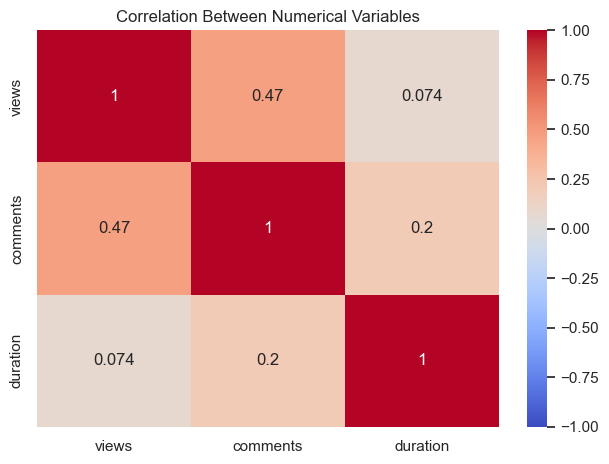

In [52]:

available_num_cols = [c for c in ["views", "comments", "duration"] if c in df.columns]

if len(available_num_cols) >= 2:
    corr = df[available_num_cols].corr(numeric_only=True)
    display(corr)

    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()

    # Save graph in the output folder
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)

    plt.savefig(
        os.path.join(output_dir, "numerical_correlation_heatmap.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


### Interpretation

- Correlation values close to **+1** show a strong positive linear relationship.
- Values close to **−1** show a strong negative linear relationship.
- Values near **0** indicate a weak linear relationship, but a non-linear relationship may still exist.
- Very popular talks can stretch the axes, so inspect scatter plots carefully. Do not claim a relationship is strong unless the output supports it.

## 15. Numerical variable vs. categorical variable

Compare views across events or native languages. To keep the charts readable, use only the top categories. Box plots show the spread and potential outliers within each group.

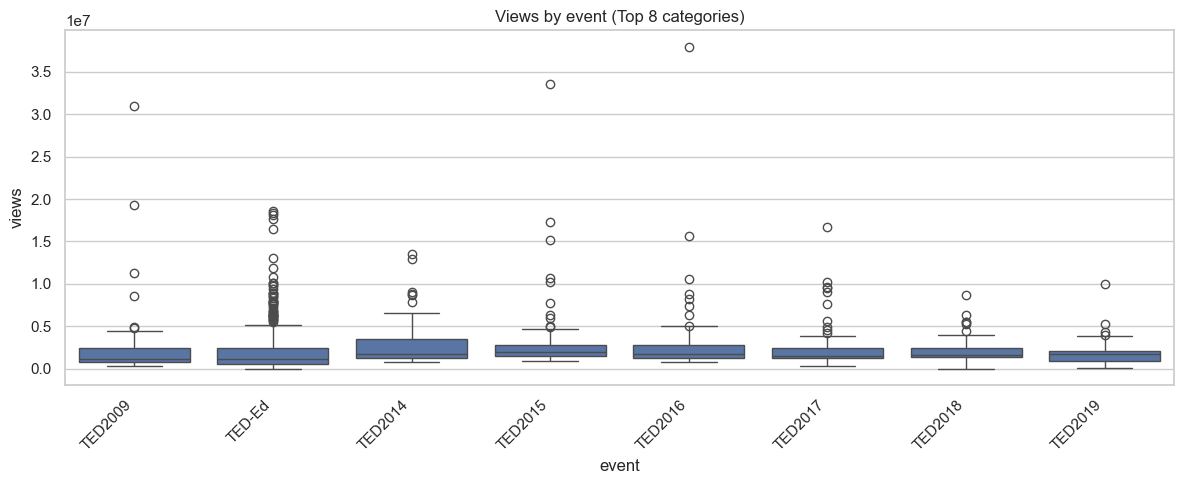

Median views by event:


,median_views
event,
TED2015,1942379.0
TED2014,1772047.0
TED2019,1750455.0
TED2016,1735984.0
TED2018,1627490.5
TED2017,1546420.5
TED2009,1191869.0
TED-Ed,1185482.5


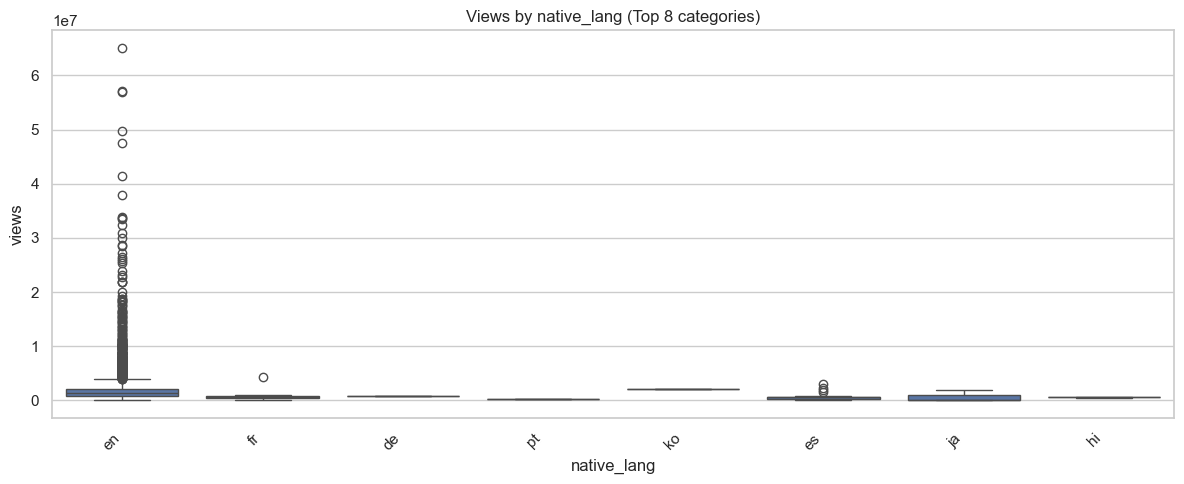

Median views by native_lang:


,median_views
native_lang,
ko,2057706.0
en,1383808.0
de,884881.0
fr,662714.0
hi,576852.0
es,548242.0
pt,347518.0
ja,112744.0


In [53]:

if "views" in df.columns:
    for cat_col in [c for c in ["event", "native_lang"] if c in df.columns]:
        top_values = df[cat_col].value_counts().head(8).index
        plot_df = df[df[cat_col].isin(top_values)][[cat_col, "views"]].dropna()

        if not plot_df.empty:
            plt.figure(figsize=(12, 5))
            sns.boxplot(data=plot_df, x=cat_col, y="views")
            plt.title(f"Views by {cat_col} (Top 8 categories)")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()

            # Save graph in the output folder
            output_dir = os.path.join(os.getcwd(), "output")
            os.makedirs(output_dir, exist_ok=True)

            plt.savefig(
                os.path.join(output_dir, f"views_by_{cat_col}_boxplot.png"),
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()

            print(f"Median views by {cat_col}:")
            display(plot_df.groupby(cat_col)["views"].median()
                    .sort_values(ascending=False).to_frame("median_views"))


## 16. Categorical variable vs. categorical variable

A cross-tabulation compares the counts of two categorical columns. Here, we compare native language and event for the most common categories. The table shows counts, not causation.

event,TED-Ed,TED2009,TED2014,TED2015,TED2016,TED2017,TED2018,TED2019
native_lang,,,,,,,,
en,556,81,84,75,75,90,96,91
es,0,0,0,0,0,5,0,0


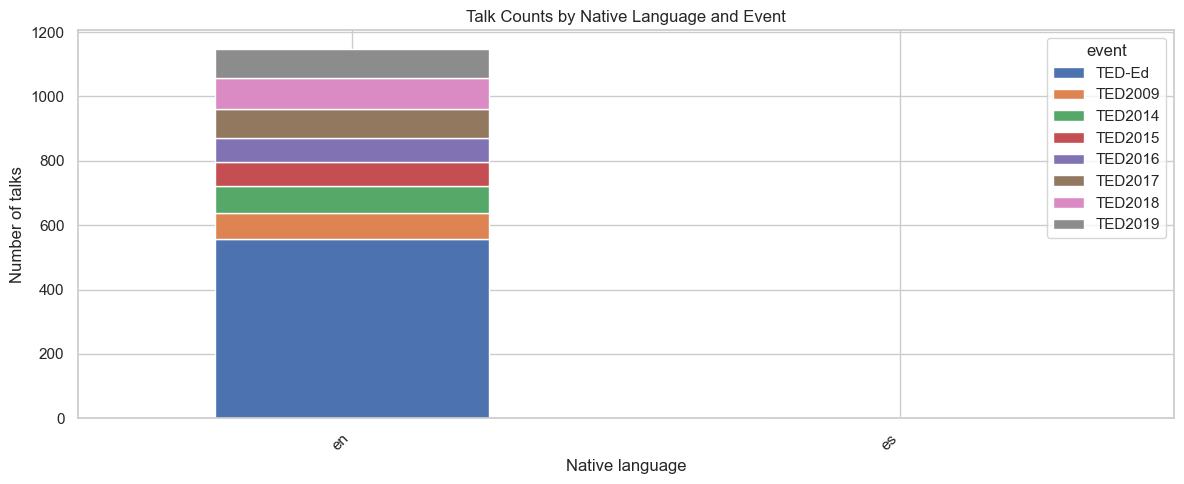

In [54]:

if "native_lang" in df.columns and "event" in df.columns:
    top_languages = df["native_lang"].value_counts().head(8).index
    top_events = df["event"].value_counts().head(8).index

    subset = df[
        df["native_lang"].isin(top_languages) &
        df["event"].isin(top_events)
    ]

    cross_tab = pd.crosstab(subset["native_lang"], subset["event"])
    display(cross_tab)

    if not cross_tab.empty:
        cross_tab.plot(kind="bar", stacked=True, figsize=(12, 5))
        plt.title("Talk Counts by Native Language and Event")
        plt.xlabel("Native language")
        plt.ylabel("Number of talks")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()

        # Save graph in the output folder
        output_dir = os.path.join(os.getcwd(), "output")
        os.makedirs(output_dir, exist_ok=True)

        plt.savefig(
            os.path.join(output_dir, "talk_counts_by_language_and_event.png"),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


## 17. Date variable vs. numerical variable

We can compare yearly talk counts and average views by publication year. Grouping by year helps smooth the individual talk records into an easy-to-read trend.

,talk_count,average_views,median_views
published_year,,,
2006,49,4.937003e+06,2060305.0
2007,119,1.848977e+06,1377588.0
2008,185,1.810979e+06,893977.0
2009,215,2.071610e+06,1083790.0
2010,230,2.188767e+06,1097755.0
2011,255,1.932456e+06,1170370.0
2012,303,2.196281e+06,1176143.0
2013,242,3.012435e+06,1597482.0
2014,240,2.423564e+06,1536921.0


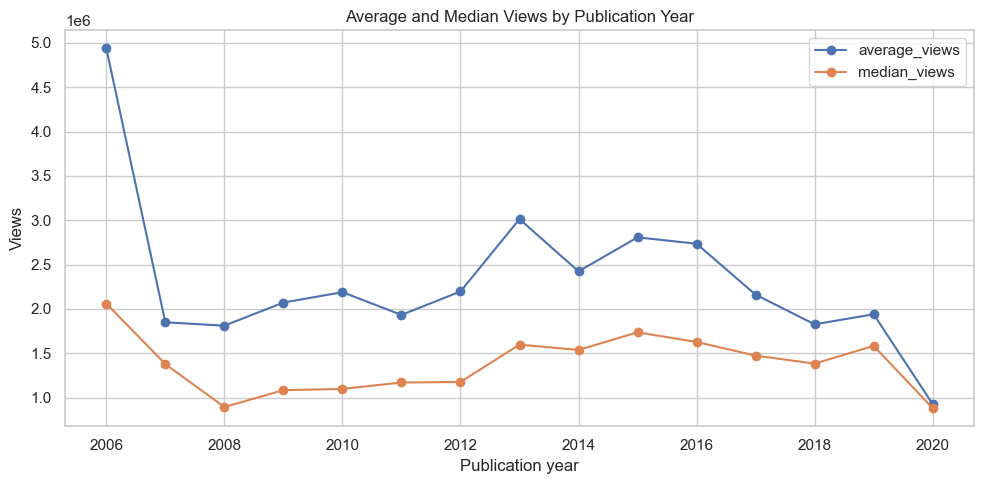

In [55]:

if "published_date" in df.columns and "views" in df.columns:
    dated_views = df.dropna(subset=["published_date", "views"]).copy()
    dated_views["published_year"] = dated_views["published_date"].dt.year

    yearly_stats = dated_views.groupby("published_year").agg(
        talk_count=("views", "size"),
        average_views=("views", "mean"),
        median_views=("views", "median")
    )

    display(yearly_stats)

    yearly_stats[["average_views", "median_views"]].plot(
        kind="line", marker="o", figsize=(10, 5)
    )
    plt.title("Average and Median Views by Publication Year")
    plt.xlabel("Publication year")
    plt.ylabel("Views")
    plt.tight_layout()

    # Save graph in the output folder
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)

    plt.savefig(
        os.path.join(output_dir, "average_median_views_by_year.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# Part C — Multivariate Analysis

**Multivariate analysis** explores patterns involving more than two variables at once. For a student-level EDA, we will use a numerical correlation heatmap, a pair plot on a manageable sample, and a grouped summary table. These methods help us see several relationships without building a complicated model.

## 18. Correlation heatmap for numerical variables

This heatmap shows the pairwise correlation of all available numerical analysis columns together. It is a simple overview of how the numerical variables relate to each other.

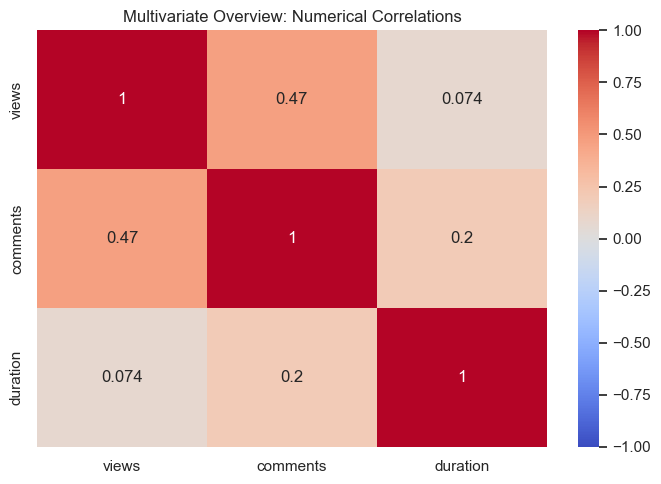

In [56]:

multi_num_cols = [c for c in ["views", "comments", "duration"] if c in df.columns]

if len(multi_num_cols) >= 2:
    multi_corr = df[multi_num_cols].corr(numeric_only=True)

    plt.figure(figsize=(7, 5))
    sns.heatmap(multi_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Multivariate Overview: Numerical Correlations")
    plt.tight_layout()

    # Save graph in the output folder
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)

    plt.savefig(
        os.path.join(output_dir, "multivariate_numerical_correlations.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("At least two numerical columns are needed for a correlation heatmap.")


## 19. Pair plot

A pair plot displays several numerical relationships in one figure. We use a sample of rows to keep it quick and readable. The diagonal shows each variable's distribution, and the other panels show scatter plots.

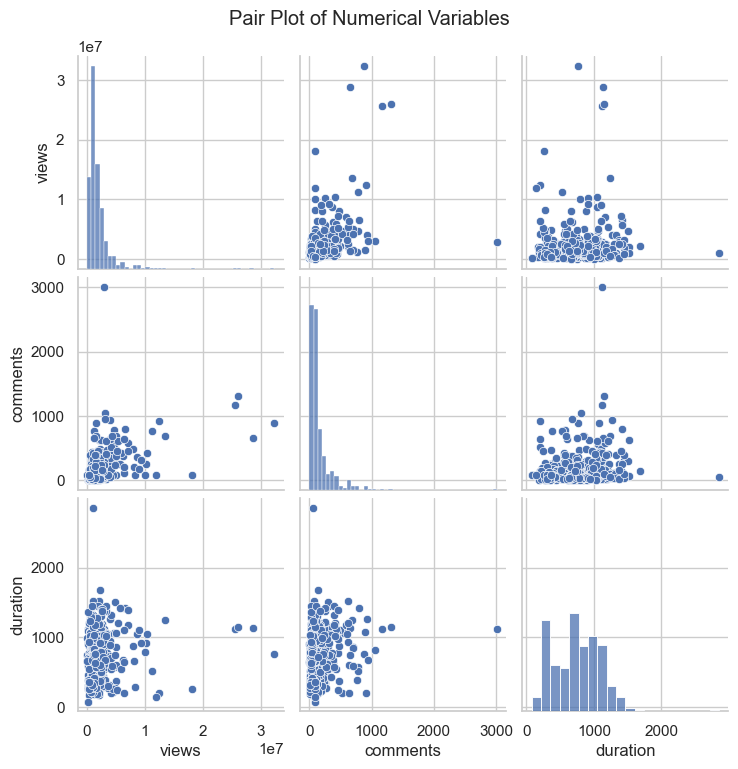

In [57]:

pair_cols = [c for c in ["views", "comments", "duration"] if c in df.columns]
pair_df = df[pair_cols].dropna()

if len(pair_cols) >= 2 and not pair_df.empty:
    sample_size = min(500, len(pair_df))
    pair_sample = pair_df.sample(n=sample_size, random_state=42) if len(pair_df) > sample_size else pair_df

    pair_plot = sns.pairplot(pair_sample)
    pair_plot.figure.suptitle("Pair Plot of Numerical Variables", y=1.02)

    # Save graph in the output folder
    output_dir = os.path.join(os.getcwd(), "output")
    os.makedirs(output_dir, exist_ok=True)

    pair_plot.figure.savefig(
        os.path.join(output_dir, "pair_plot_numerical_variables.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("Not enough numerical data for a pair plot.")


## 20. Grouped analysis using several columns

This table examines multiple variables together: publication year, native language, number of talks, median views and median comments. We limit the output to the most common language categories to make it easier to read.

In [31]:
if all(c in df.columns for c in ["published_date", "native_lang", "views", "comments"]):
    group_df = df.dropna(
        subset=["published_date", "native_lang", "views", "comments"]
    ).copy()
    group_df["published_year"] = group_df["published_date"].dt.year

    top_languages = group_df["native_lang"].value_counts().head(5).index
    group_df = group_df[group_df["native_lang"].isin(top_languages)]

    grouped_summary = group_df.groupby(
        ["published_year", "native_lang"]
    ).agg(
        talk_count=("talk_id", "count") if "talk_id" in group_df.columns else ("views", "count"),
        median_views=("views", "median"),
        median_comments=("comments", "median")
    ).reset_index()

    display(grouped_summary.head(20))
else:
    print("Some required columns for this grouped analysis are missing.")

,published_year,native_lang,talk_count,median_views,median_comments
0,2006,en,49,2060305.0,168.0
1,2007,en,119,1377588.0,121.0
2,2008,en,185,893977.0,85.0
3,2009,en,215,1083790.0,132.0
4,2010,en,230,1097755.0,211.5
5,2011,en,251,1183041.0,200.0
6,2011,fr,2,612322.5,100.0
7,2012,en,303,1176143.0,148.0
8,2013,en,239,1597877.0,211.0
9,2013,fr,1,665239.0,131.0


### How to interpret multivariate results

Look for patterns that involve several fields together. For example, compare whether median views differ by language and publication year. Always consider the number of talks in each group: a result based on very few talks may not be representative.

This is descriptive analysis. It does not establish that language, event, or duration causes a talk to receive more views.

# Part D — Basic Cleaning and Preparation

Cleaning decisions should be based on what we learned from EDA. We keep the original `df` and create `df_clean` as a separate copy. We avoid filling all missing values blindly or deleting all potential outliers.

## 21. Create a cleaned copy and standardize text

This step standardizes whitespace in text columns. It does not replace a full manual review of missing values, duplicates, or unusual records.

In [33]:

df_clean = df.copy()

# Standardize whitespace in selected text columns
clean_text_cols = [
    c for c in ["title", "all_speakers", "about_speakers",
                "description", "transcript"]
    if c in df_clean.columns
]

for col in clean_text_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

print("Cleaned copy created.")
print("Rows before duplicate check:", len(df_clean))

# Convert list values into tuples temporarily for duplicate checking
df_check = df_clean.copy()

for col in df_check.columns:
    df_check[col] = df_check[col].apply(
        lambda x: tuple(x) if isinstance(x, list) else x
    )

print("Exact duplicate rows:", df_check.duplicated().sum())


Cleaned copy created.
Rows before duplicate check: 4005
Exact duplicate rows: 0


### 21.1 Remove exact duplicate rows (only if appropriate)

The next cell removes exact duplicate rows. If duplicate rows have a meaningful reason to exist in your dataset, do not run this step without reviewing them first. Duplicate `talk_id` values should also be investigated separately.

In [35]:

# Create a temporary copy for duplicate checking
df_check = df_clean.copy()

# Convert lists into tuples so pandas can compare them
for col in df_check.columns:
    df_check[col] = df_check[col].apply(
        lambda x: tuple(x) if isinstance(x, list) else x
    )
# Identify exact duplicate rows
duplicate_mask = df_check.duplicated(keep="first")

print("Exact duplicate rows found:", duplicate_mask.sum())

# Remove duplicate rows from the original cleaned DataFrame
df_clean = df_clean.loc[~duplicate_mask].copy()

print("Rows after removing exact duplicates:", len(df_clean))

# Check for duplicate talk IDs separately
if "talk_id" in df_clean.columns:
    print(
        "Duplicate talk IDs remaining:",
        df_clean["talk_id"].duplicated().sum()
    )


Exact duplicate rows found: 0
Rows after removing exact duplicates: 4005
Duplicate talk IDs remaining: 0


## 22. Create `combined_text` for recommendations

For a basic content-based recommendation system, combine the talk's title, topics, description and transcript. Missing values are treated as empty text for this combined field. This is a starting feature, not the recommendation model itself.

In [36]:
combine_cols = [c for c in ["title", "topics", "description", "transcript"]
                if c in df_clean.columns]

if combine_cols:
    for col in combine_cols:
        df_clean[col] = df_clean[col].fillna("").astype(str)

    df_clean["combined_text"] = df_clean[combine_cols].agg(" ".join, axis=1)
    display(df_clean[[c for c in ["talk_id", "title", "combined_text"]
                      if c in df_clean.columns]].head())
else:
    print("No columns were found for combined_text.")

,talk_id,title,combined_text
0,1,Averting the climate crisis,Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,"The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,"Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,"Do schools kill creativity? ['children', 'crea..."


## 23. Save the cleaned dataset

The output CSV will be saved in the notebook's current working directory. Confirm that the file was created and check its shape before using it for the next project stage.

In [37]:
output_file = "ted_talks_cleaned.csv"
df_clean.to_csv(output_file, index=False)

print("Saved:", output_file)
print("Cleaned dataset shape:", df_clean.shape)

# Read it back to confirm it can be opened
check_df = pd.read_csv(output_file)
print("Saved file shape:", check_df.shape)
display(check_df.head())

Saved: ted_talks_cleaned.csv
Cleaned dataset shape: (4005, 30)
Saved file shape: (4005, 30)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript,published_year,title_word_count,description_word_count,transcript_word_count,about_speakers_word_count,topic_list,topic_count,available_lang_count,related_talk_list,related_talk_count,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",2006,4,39,2153,24,"['alternative energy', 'cars', 'climate change...",9,43,"[""{243: 'New thinking on the climate crisis"", ...",6,Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",2006,6,26,3174,35,"['Africa', 'Asia', 'Google', 'demo', 'economic...",11,49,"['{2056: ""Own your body\'s data', ""2296: 'A vi...",6,"The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",2006,2,31,3371,45,"['computers', 'entertainment', 'interface desi...",9,26,"[""{1725: '10 top time-saving tech tips"", ""2274...",6,"Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,2006,3,31,3071,32,"['MacArthur grant', 'activism', 'business', 'c...",9,35,"[""{1041: '3 stories of local eco-entrepreneurs...",6,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,2006,4,21,3170,32,"['children', 'creativity', 'culture', 'dance',...",7,62,"[""{865: 'Bring on the learning revolution!"", '...",7,"Do schools kill creativity? ['children', 'crea..."


# Part E — Final EDA Findings

Use the actual outputs from your notebook to fill in the observations below. Do not write conclusions before checking the charts and tables.

## 24. Findings template

### Dataset overview
- Total rows and columns:
- Most important columns for the project:
- Columns with the most missing values:

### Numerical analysis
- Distribution of views:
- Distribution of comments:
- Distribution of duration:
- Potential outliers that need investigation:

### Categorical and topic analysis
- Most common native language:
- Most common events:
- Most common occupations:
- Most common topics:
- Most frequent primary speakers:

### Text analysis
- Missing or empty text entries:
- Short or unusually long transcripts:
- Most frequent meaningful words:
- Are transcripts usable for recommendations?

### Date analysis
- Earliest and latest publication dates:
- Year with the most published talks:
- Any date-quality issues:

### Bivariate and multivariate analysis
- Relationship between views and comments:
- Relationship between duration and views:
- Any differences in views across events or languages:
- Patterns observed when comparing multiple variables:

### Data quality and preparation
- Missing values handled:
- Duplicate rows reviewed:
- Text standardization performed:
- `combined_text` created:
- Cleaned CSV saved:

### Recommendation-system readiness
- Useful content columns: `title`, `topics`, `description`, `transcript`
- Possible supporting columns: `speaker_1`, `event`, `native_lang`
- Remaining issues to fix before modeling:

## 25. Final reminder

EDA is not just creating plots. For each important chart or table:

1. State what you checked.
2. Show the result.
3. Write one or two sentences explaining what the result means.
4. Mention any data-quality issue or limitation.

This notebook is intentionally kept at a student-friendly level. Once the data is understood and cleaned, the next step can be to build a simple content-based recommender using text features.